# Plotting Inference Results

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, Any

In [2]:
def fetch_inferences(model_type: str, data_type: str) -> pd.DataFrame:
    """
    Fetches the inferences dataframe of the model with the given model_type trained on the given data_type

    Args:
        model_type (str): Type of the model. One of 'CNN', 'FNOtoScalar', 'PhysicsFNO'.
        data_type (str): Type of data the model was trained on. One of 'Hmaps', 'Images'

    Returns:        
        pd.Dataframe: Dataframe containing all predictions and the corresponding targets, as well as the elementwise MAE, MSE and MRE.
    """

    # Fetch the correct model code
    if data_type == "Hmaps":
        if model_type == "CNN":
            # CNN, hmap
            model_code = "2025-09-04-11-06-45"
            inference_code = "04-15-37-12"
        elif model_type == "PhysicsFNO":
            # physics FNO, Hmaps
            model_code = "2025-09-03-22-57-41" 
            inference_code = "04-15-18-28"
        elif model_type == "FNOtoScalar":
            # FNO to scalar, Hmaps
            model_code = "2025-09-03-20-57-36" 
            inference_code = "04-15-20-05"
        else:
            raise ValueError("Unknown model type for hmap data")
    elif data_type == "Images":
        if model_type == "CNN":
            # CNN, image
            model_code = "2025-09-04-11-16-40" 
            inference_code = "04-15-41-35"
        elif model_type == "PhysicsFNO":
            # physics FNO, Images
            model_code = "2025-09-04-08-27-59" 
            inference_code = "04-15-07-15"
        elif model_type == "FNOtoScalar":
            # FNO to scalar, Images
            model_code = "2025-09-03-22-53-35" 
            inference_code = "04-15-30-03"
        else:
            raise ValueError("Unknown model type for image data")
    else:
        raise ValueError("Unknown data type")

    # fetch the matching inferences
    inference_path = f"logs/{model_code}/{inference_code}_best_model_test_inferences.csv" 
    df = pd.read_csv(inference_path)

    return df

In [3]:
model_type = "PhysicsFNO" # CNN, PhysicsFNO or FNOtoScalar
data_type = "Hmaps" # Hmaps or Images 

df = fetch_inferences(model_type, data_type)
df.describe()

,targets_100,preds_100,mae_100,mse_100,mre_100,targets_125,preds_125,mae_125,mse_125,mre_125,...,targets_3150,preds_3150,mae_3150,mse_3150,mre_3150,targets_4000,preds_4000,mae_4000,mse_4000,mre_4000
count,6566.000000,6566.000000,6566.000000,6.566000e+03,6566.000000,6566.000000,6566.000000,6.566000e+03,6.566000e+03,6566.000000,...,6566.000000,6566.000000,6566.000000,6.566000e+03,6566.000000,6566.000000,6566.000000,6566.000000,6.566000e+03,6566.000000
mean,0.732618,0.736630,0.009037,2.382972e-04,1.261156,0.723129,0.727198,9.235685e-03,2.459632e-04,1.304551,...,0.183149,0.195211,0.061786,5.883622e-03,47.539589,0.174745,0.187965,0.063477,6.181069e-03,55.763013
std,0.017181,0.004934,0.012516,8.011643e-04,1.804583,0.017479,0.005022,1.267635e-02,8.228232e-04,1.838828,...,0.081998,0.020228,0.045458,9.214999e-03,61.780199,0.084468,0.020485,0.046391,9.766875e-03,82.691526
min,0.640350,0.732677,0.000003,7.847944e-12,0.000376,0.636394,0.723222,7.748604e-07,6.004086e-13,0.000107,...,0.022318,0.182579,0.000003,6.800116e-12,0.001426,0.014618,0.174481,0.000010,9.323742e-11,0.005500
25%,0.726170,0.732790,0.002213,4.898496e-06,0.299368,0.716388,0.723323,2.272159e-03,5.162706e-06,0.312092,...,0.123027,0.182732,0.026633,7.093388e-04,13.880802,0.111339,0.174672,0.027670,7.656021e-04,14.885962
50%,0.735245,0.733690,0.004789,2.293333e-05,0.649024,0.725622,0.724167,4.917413e-03,2.418096e-05,0.675096,...,0.169769,0.183601,0.054802,3.003281e-03,29.029067,0.161273,0.175815,0.056202,3.158701e-03,32.078913
75%,0.742682,0.740570,0.009880,9.761366e-05,1.343525,0.733250,0.731189,1.020725e-02,1.041880e-04,1.406082,...,0.231412,0.199329,0.087080,7.582896e-03,56.387994,0.223447,0.194577,0.089538,8.017111e-03,62.047010
max,0.840666,0.748875,0.107977,1.165908e-02,14.807505,0.852618,0.739695,1.293764e-01,1.673826e-02,15.174023,...,0.600147,0.251094,0.414560,1.718600e-01,718.315000,0.564342,0.246052,0.386066,1.490469e-01,1093.914600


In [4]:
frequencies = [100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000]
frequencies_str = ['100','125','160','200','250','315','400','500','630','800','1000','1250','1600','2000','2500','3150','4000']
losses = ['mae', 'mse', 'mre']

## Comparing Predictions

In [5]:
pred = df[[f'preds_{freq}' for freq in frequencies]]
pred.describe()

,preds_100,preds_125,preds_160,preds_200,preds_250,preds_315,preds_400,preds_500,preds_630,preds_800,preds_1000,preds_1250,preds_1600,preds_2000,preds_2500,preds_3150,preds_4000
count,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000,6566.000000
mean,0.736630,0.727198,0.712510,0.695713,0.677522,0.663467,0.639348,0.538512,0.422229,0.403955,0.368710,0.334015,0.282204,0.224236,0.199698,0.195211,0.187965
std,0.004934,0.005022,0.005060,0.006107,0.007852,0.011988,0.016112,0.011136,0.010761,0.023827,0.033376,0.034634,0.027917,0.019185,0.016870,0.020228,0.020485
min,0.732677,0.723222,0.708501,0.691137,0.671743,0.654681,0.628161,0.531570,0.416403,0.388675,0.345511,0.307567,0.260054,0.207233,0.187876,0.182579,0.174481
25%,0.732790,0.723323,0.708590,0.691245,0.671842,0.654803,0.628276,0.531639,0.416464,0.388820,0.345679,0.307750,0.260281,0.207832,0.188223,0.182732,0.174672
50%,0.733690,0.724167,0.709352,0.692066,0.672654,0.655880,0.629211,0.532048,0.416585,0.389330,0.346490,0.309503,0.263095,0.212950,0.190113,0.183601,0.175815
75%,0.740570,0.731189,0.716956,0.699534,0.682706,0.672053,0.649644,0.540377,0.420073,0.413342,0.396443,0.374096,0.311155,0.241441,0.206231,0.199329,0.194577
max,0.748875,0.739695,0.724232,0.710169,0.694722,0.687666,0.672437,0.564427,0.451564,0.456633,0.433695,0.396394,0.336619,0.271501,0.246407,0.251094,0.246052


In [6]:
for freq in frequencies:
    print(f"Number of unique values for frequency {freq}: {pred[f'preds_{freq}'].nunique()}")

Number of unique values for frequency 100: 5782
Number of unique values for frequency 125: 5685
Number of unique values for frequency 160: 5629
Number of unique values for frequency 200: 5737
Number of unique values for frequency 250: 5717
Number of unique values for frequency 315: 5854
Number of unique values for frequency 400: 5821
Number of unique values for frequency 500: 5464
Number of unique values for frequency 630: 5550
Number of unique values for frequency 800: 6184
Number of unique values for frequency 1000: 6218
Number of unique values for frequency 1250: 6282
Number of unique values for frequency 1600: 6367
Number of unique values for frequency 2000: 6519
Number of unique values for frequency 2500: 6480
Number of unique values for frequency 3150: 6363
Number of unique values for frequency 4000: 6403


## Plotting Losses by Frequency

In [7]:
def performance_by_freq(df: pd.DataFrame) -> tuple[Dict[str, np.array], Dict[str, float]]:
    """
    Computes for all losses the the mean performance per frequency and overall mean performance.

    Args:
        df (pd.Dataframe): Dataframe containing all predictions and the corresponding targets, as well as the elementwise MAE, MSE and MRE.

    Returns:        
        Dict[str, np.array]: Dictionary containing for each of the three loss types an array with the mean loss per frequency.
        Dict[str, float]: Dictionary containing the mean loss over all frequencies for each of the 3 loss types.
    """
    # print("Computing performance by frequency...")
    mean_mae_by_freq = np.zeros(len(frequencies))
    mean_mse_by_freq = np.zeros(len(frequencies))
    mean_mre_by_freq = np.zeros(len(frequencies))
    for i, freq in enumerate(frequencies):
        mean_mae_by_freq[i] = df[f'mae_{freq}'].mean()
        mean_mse_by_freq[i] = df[f'mse_{freq}'].mean()
        mean_mre_by_freq[i] = df[f'mre_{freq}'].mean()

    mean_mae = np.mean(mean_mae_by_freq)
    mean_mse = np.mean(mean_mse_by_freq)
    mean_mre = np.mean(mean_mre_by_freq)

    perf_by_freq = {"MAE": mean_mae_by_freq, "MSE": mean_mse_by_freq, "MRE": mean_mre_by_freq}
    mean_perf = {"MAE": mean_mae, "MSE": mean_mse, "MRE": mean_mre}

    return perf_by_freq, mean_perf

In [8]:
# fetch performance by frequency
perf_by_freq, mean_perf = performance_by_freq(df)
mean_mae_by_freq = perf_by_freq["MAE"]
mean_mse_by_freq = perf_by_freq["MSE"]
mean_mre_by_freq = perf_by_freq["MRE"]
mean_mae = mean_perf["MAE"]
mean_mse = mean_perf["MSE"]
mean_mre = mean_perf["MRE"]

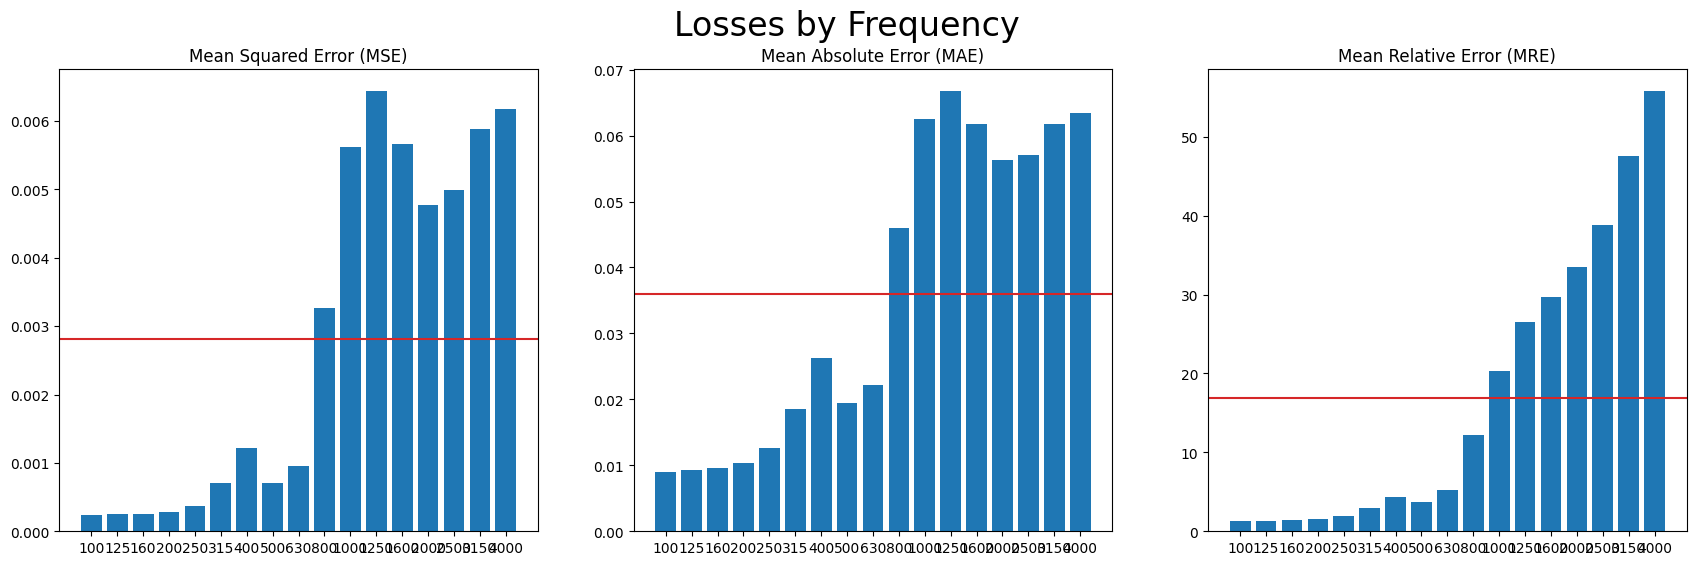

In [9]:
# plot performance per frequency for all three losses
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21,6))

f.suptitle('Losses by Frequency', fontsize=24)
ax1.bar(frequencies_str, mean_mse_by_freq)
ax1.set_title('Mean Squared Error (MSE)')
ax1.axhline(mean_mse, color='tab:red', label='Mean MSE')
ax2.bar(frequencies_str, mean_mae_by_freq)
ax2.set_title('Mean Absolute Error (MAE)')
ax2.axhline(mean_mae, color='tab:red', label='Mean MAE')
ax3.bar(frequencies_str, mean_mre_by_freq)
ax3.set_title('Mean Relative Error (MRE)')
ax3.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()

In [10]:
def plot_perf_by_freq(perf_by_freq: np.array, mean_perf: float, ax: Any, title: str=None, label:str=None) -> None:
    """
    Creates a bar chart for the performance by frequency with a horizontal bar for the mean performance at the given axis of the plot.

    Args:
        perf_by_freq (np.array): Array containing the mean loss per frequency.
        mean_perf (float): The mean loss over all frequencies. Will be plotted as a horizontal line.
        ax (Any): Axis of the figure to plot to.
        title (str): Optional Title of the figure
        label (str): Optional Label of the horizontal bar.
    Returns:        
        None
    """
    # print(f"Plotting {title}")
    ax.bar(frequencies_str, perf_by_freq, color="tab:blue")
    if title:
        ax.set_title(title, fontsize=24)
    ax.axhline(mean_perf, color='tab:red', label=label)



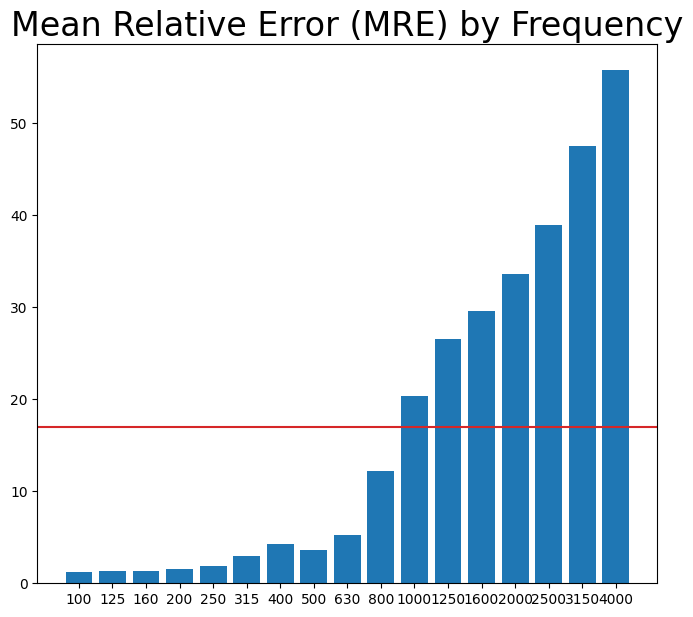

In [11]:
f, ax1 = plt.subplots(1, 1, figsize=(8,7))

plot_perf_by_freq(mean_mre_by_freq, mean_mre, ax1, title='Mean Relative Error (MRE) by Frequency', label='Mean MRE')

# plt.yticks([])

plt.show()

## Comparing models

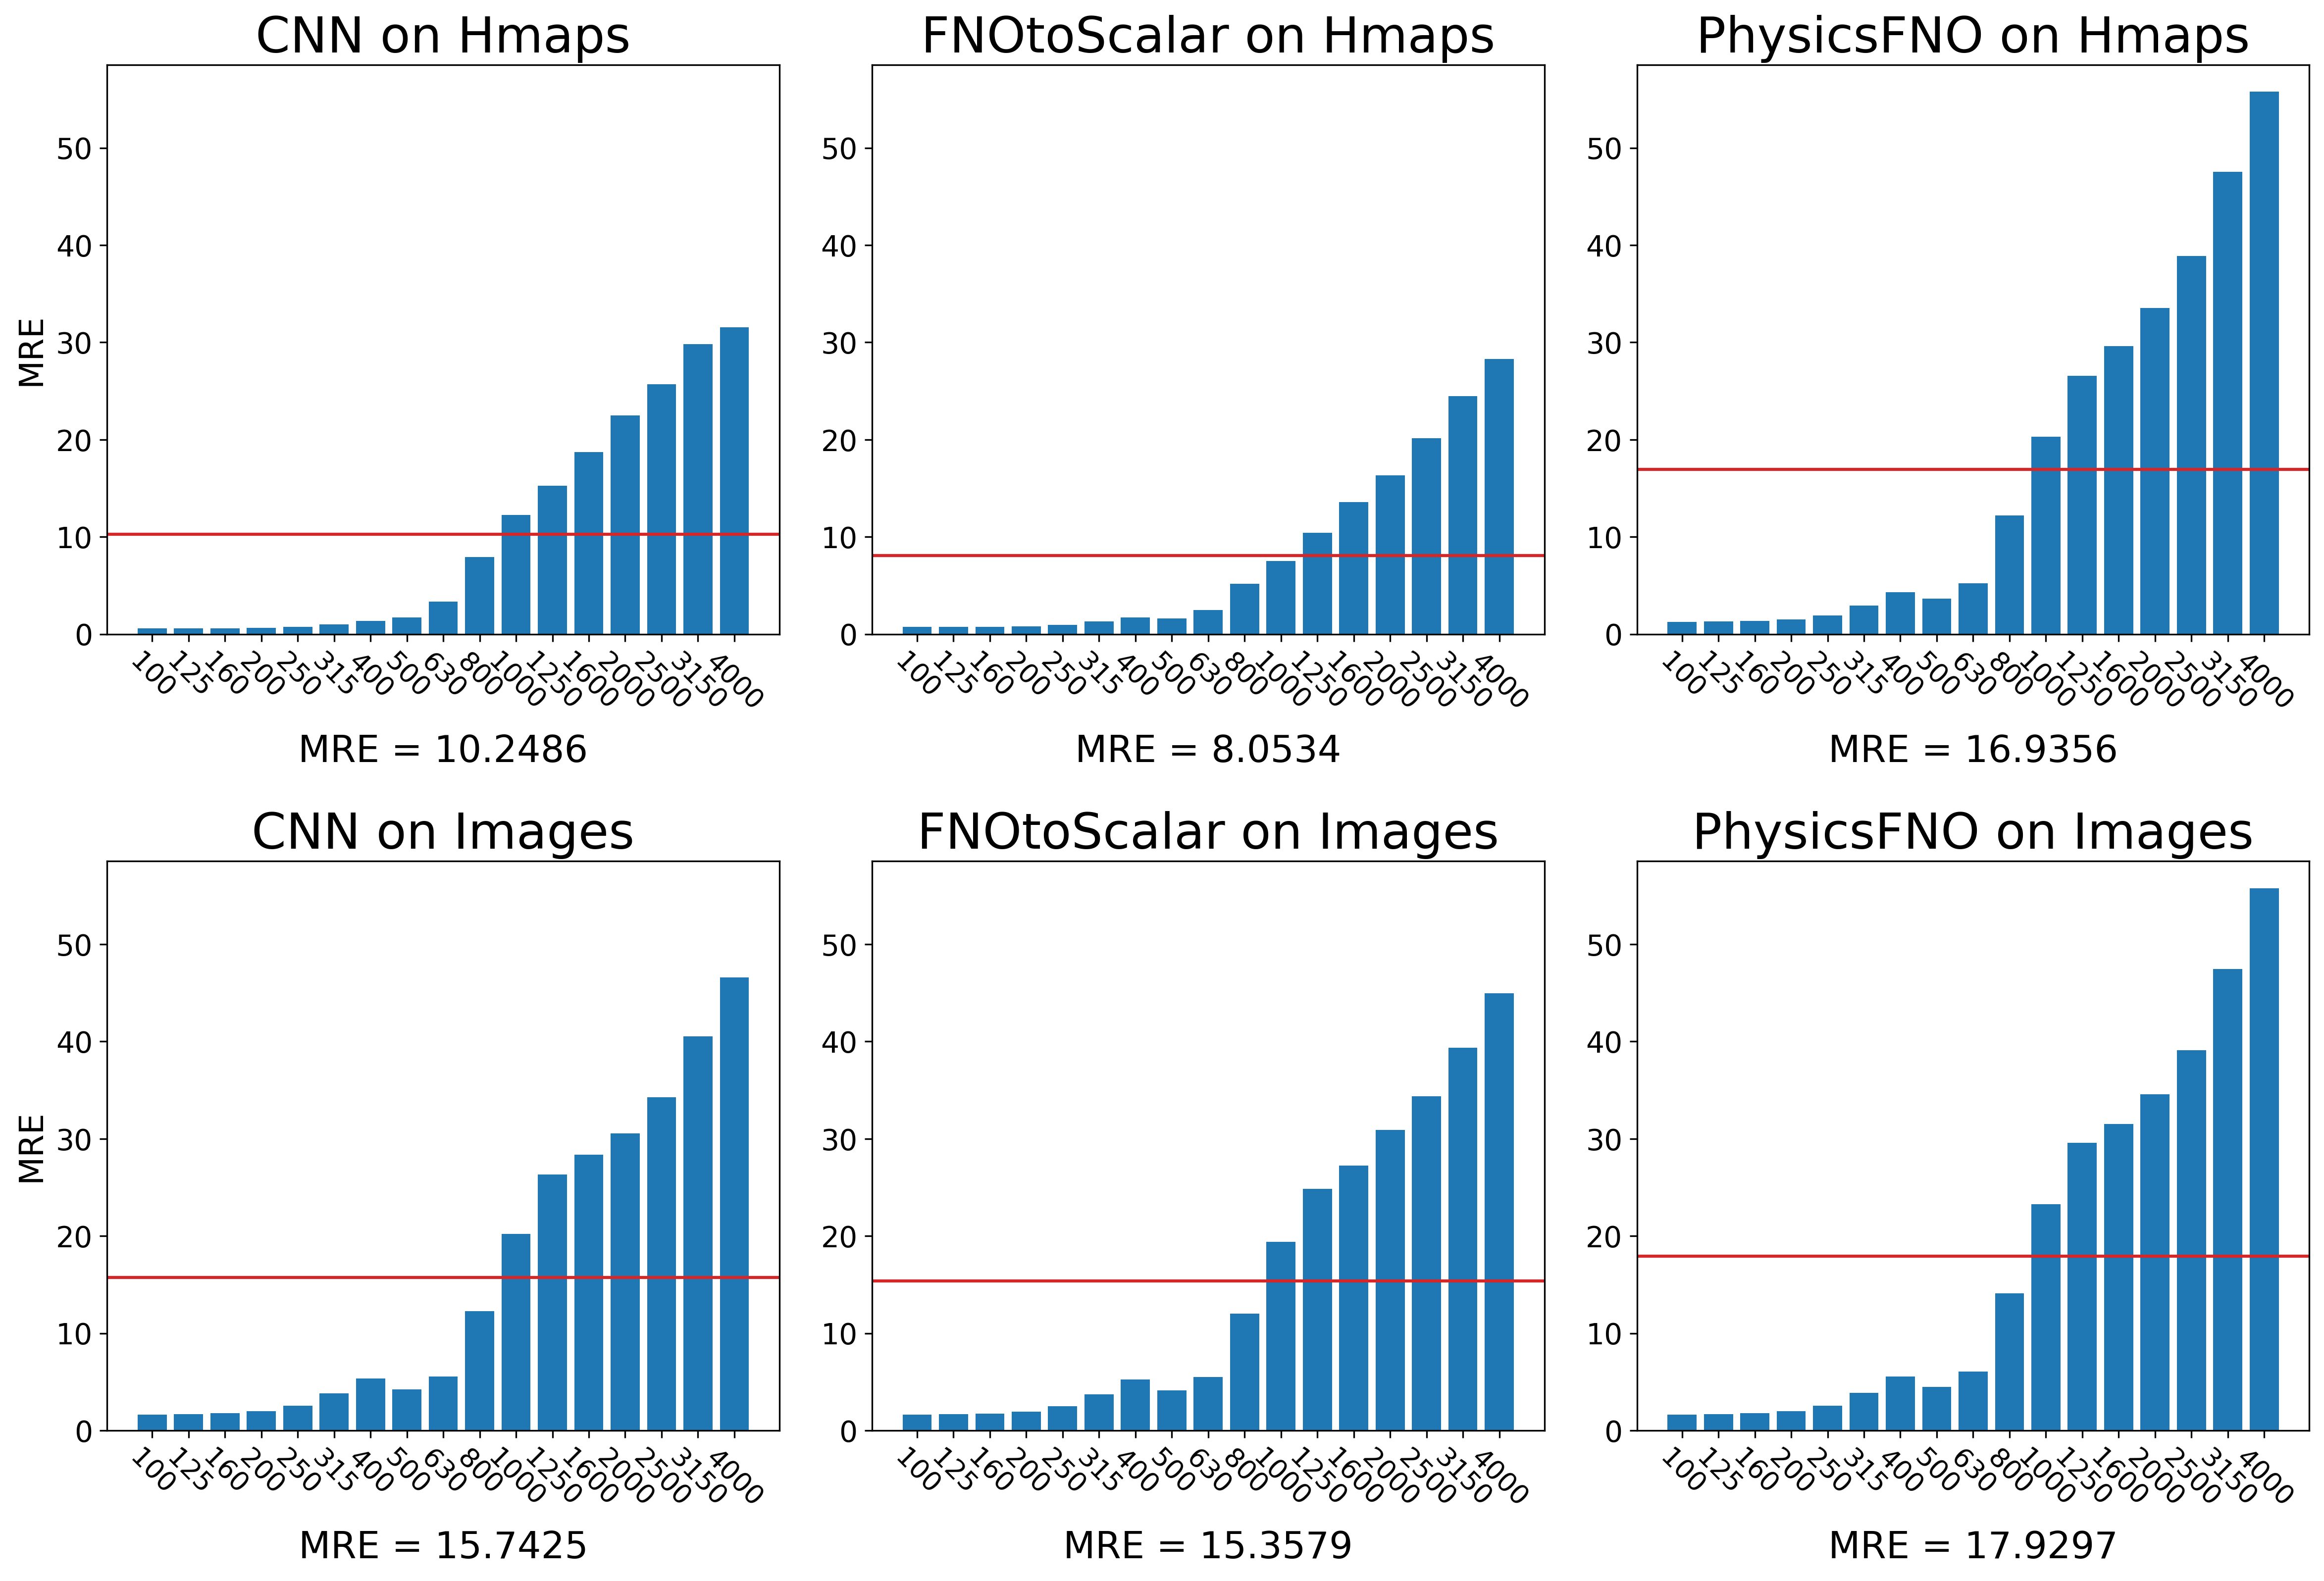

In [12]:
# plot performance per frequency of all models on all datatypes in a single plot
fig, axes = plt.subplots(2, 3, figsize=(16, 11), sharey=True, dpi=300)  # 3 rows, 2 columns

model_types = ["CNN", "FNOtoScalar", "PhysicsFNO"]
data_types = ["Hmaps", "Images"]
loss_type = "MRE"

# axes is a 2D array: shape (3, 2)
for i in range(3):
    for j in range(2):
        model = model_types[i]
        data = data_types[j]
        df = fetch_inferences(model, data)
        perf_by_freq, mean_perf = performance_by_freq(df)
        ax = axes[j, i]
        plot_perf_by_freq(perf_by_freq[loss_type], mean_perf[loss_type], ax, title=f"{model} on {data}")
        ax.yaxis.set_tick_params(labelleft=True, labelsize=14)
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=-45)
        ax.xaxis.set_tick_params(labelsize=13)
        if loss_type == "MRE":
            ax.set_xlabel(f"{loss_type} = {mean_perf[loss_type]:.4f}", fontsize=18, labelpad=9)
        else: 
            ax.set_xlabel(f"{loss_type} = {mean_perf[loss_type]:.4e}", fontsize=18, labelpad=9)

for i, ax in enumerate(axes[:, 0]):  # left column
    ax.set_ylabel(loss_type, fontsize=16)

plt.tight_layout(pad=2)